In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [5]:
df = pd.read_csv('big5-clean.csv')
df.shape

(2889, 27)

In [4]:
df.columns

Index(['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP',
       'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt',
       'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP',
       'PrgR'],
      dtype='str')

# THE MEAN (AVERAGE)
##### The Balance Point, This is the classic average. You add all the numbers together and divide by the total count of numbers.
##### THE DATA MAY BE SKIEWED DUE TO VERY BIG / SMALL DATA
##### The mean completely distorts the reality of the diner—it says the "average" person in the diner is a multi-millionaire, which isn't true. The median and mode protect you from that distortion, giving you a much more accurate reflection of what a typical person in that room actually earns.

In [11]:
fw_L30_mean = df[(df['Age'] < 30 ) & (df['Pos'].str.contains('FW'))]['Gls'].mean().round(2)
print(fw_L30_mean)

3.19


In [12]:
fw_A30_mean = df[(df['Age'] >= 30 ) & (df['Pos'].str.contains('FW'))]['Gls'].mean().round(2)
print(fw_A30_mean)

4.23


# THE MEDIAN (MIDDLE POINT AFTER SORTING)
##### The Middle Point, This is the exact middle number when your dataset is lined up in order from smallest to largest.

In [15]:
fw_A30_median = df[(df['Age'] >=30  ) & (df['Pos'].str.contains('FW'))]['Gls'].median().round(2)
print(fw_A30_median)

2.0


# THE MODE (MOST COMMON OF THE DATA)
##### The Most Frequent, This is the number that appears most often in your dataset.

In [20]:
fw_mode = df['Age'].mode()
print(fw_mode)

0    25
Name: Age, dtype: int64


# THE VARIANCE
##### **Definition**: Variance is the average of the squared differences between each data point and the mean.

##### **Why square the numbers?** If you just add up how far each number is from the mean, positive and negative differences cancel each other out to zero. Squaring the differences makes them all positive.

##### Variance tells us how spread out the data is around its mean. A low variance means the values tend to be close to the mean; a high variance means they are more spread out.

![Variance and standard deviation](var-std-ste.png)

In [22]:
df['Gls'].var()

np.float64(9.972899161879669)

# STANDARD DEVIATION 
#### **Definition**: Standard deviation is the square root of the variance.
#### **Why use it?** Taking the square root "undoes" the squaring from the variance step. This brings the measurement back to the original units of your data (like meters, seconds, or dollars), making it much easier to interpret
#### **What it tells you:**
    • It represents a typical or average distance that data points fall away from the mean.
    • A small standard deviation means the data points are tightly clustered close to the mean.
    • A large standard deviation means the data points are spread out over a wide range of values.
##### because standard deviation is just the square root of the variance. So what standard deviation kind of allows us to do is to as well gives us a metric of how spread out is our data. And usually with normal data, we hope to have most of the data within about three standard deviations. And anything outside of those three standard deviations is usually considered an outlier or a data point that might not that we might not want to include in our analysis or if we're training different models so that we don't train it on bad or rare data points. Okay? Because we're trying to basically with these statistics make sure that we have the most correct information and you will always have outliers in your data. But it's important to be able to handle those as much as you can. So in pandas once again it's very simple to calculate the standard deviation. 

In [25]:
df['Gls'].std()


np.float64(3.157989734289785)

# THE PERCENTILE
##### A statistical measure that tells you what percentage of the data falls below a specific value. It is used to understand how a single score or value compares to the rest of a group.

##### **How to Understand It**
    • If you score in the 90th percentile on a test, it means you scored better than 90% of the people who took it. It does not mean you got a 90% on the test; it just means only 10% scored higher than you.
    • The 50th percentile is the exact middle of the data, also known as the median. Half the scores are below it, and half are above it.

In [28]:
df['Gls'].quantile(0.99)


np.float64(15.0)

# THE SKEW
#### The skew (or skewness) of a distribution measures its asymmetry. It tells you whether the data is distributed evenly around the center, or if it "leans" and stretches out more on one side than the other.
#### The easiest way to identify skewness is to look at the tail (the long, tapering end of the curve), not the main hump. The direction of that tail tells you the type of skew.
#### skew basically tells us if we have any sort of tail ends or if the distribution is normalized in the middle. So to do this and kind of see the skew of our data in pandas, we can do it very simply if we just say df goals do skew like this. And so we have a positive number. And so what a positive number means is that our data is skewed to the right. Or in other words, it means that our data is mostly closer to the lower values and it kind of is shaped as it has that tail going off to the right side of the graph. If it was negative, then we would have a left skew or a negative skew, which means that basically more of our data is on the right side of the metric.


#### **The Three Types of Skew**

#### **1. Positive Skew (Right-Skewed)**
    • What it looks like: The main hump is on the left, and the long tail stretches out to the right (toward higher positive values).
    • The Math: A few unusually high values (outliers) drag the average upward. Because of this, the Mean is greater than the Median (Mean > Median).
    • Real-World Example: Household income. Most people earn a modest or average salary (the hump on the left), while a tiny handful of billionaires create a long tail stretching far to the right.

#### **2. Negative Skew (Left-Skewed)**
    • What it looks like: The main hump is on the right, and the long tail stretches out to the left (toward lower negative values).
    • The Math: A few unusually low values pull the average down. This means the Mean is less than the Median (Mean < Median).
    • Real-World Example: Age of retirement or human lifespan. Most people live into their 70s or 80s (the hump on the right), but a smaller number of people dying tragically young creates a tail pointing out to the left.

#### **3. Zero Skew (Symmetrical)**
    • What it looks like: A perfectly balanced, mirror-image bell curve.
    • The Math: The Mean, Median, and Mode are all exactly the same value in the dead center.
    • Real-World Example: Adult heights or IQ scores. Most people cluster right around the middle average, with an equal drop-off of exceptionally short/tall or low/high scores on both sides.


### **Why Does Skewness Matter?**
Many standard statistical tools and financial calculators assume that data follows a perfectly symmetrical, normal distribution. If your data is heavily skewed, using those tools without adjusting the data first can lead to highly inaccurate predictions or distorted results.

![Skew Type](skew.png)



In [29]:
df['Gls'].skew()


np.float64(3.578540247914825)

# THE CORRELATION
##### In statistics, correlation is a measure that describes how two different datasets or variables change together. While concepts like variance, standard deviation, and skewness describe the shape and spread of a single distribution, correlation acts as a bridge that looks at the relationship between two distributions. It tells you if a pattern in one distribution predicts a pattern in another

#### **1. The Direction of Correlation**
##### Correlation is calculated as a number (called the correlation coefficient, or r) that always falls between -1 and +1. The sign of the number shows the direction of the relationship:
####    • **Positive Correlation (Between 0 and +1):** 
    Both variables move in the same direction. When values in the first distribution go up, values in the second distribution tend to go up too.
    • Example: Temperature and ice cream sales. As the weather gets hotter, ice cream sales rise.
    • Negative Correlation (Between -1 and 0): The variables move in opposite directions. When one goes up, the other goes down.
    • Example: Temperature and heating bills. As the weather gets hotter, heating bills go down.
    • Zero Correlation (Exactly 0): There is no linear relationship between the two distributions. A change in one tells you nothing about the other.
    • Example: The amount of coffee you drink and your shoe size

#### **2. The Golden Rule: Correlation != Causation**
    Just because two distributions change together does not mean one causes the other to happen.
    For example, swimming pool accidents and ice cream sales are highly positively correlated—they both spike at the same time of year. However, eating ice cream doesn't cause pool accidents. Instead, a third variable (hot summer weather) is driving both distributions upward at the same time

#### So in correlation we are basically measuring the relationship between two different variables two or more variables. And what we're doing is basically saying what is the strength of this relationship. We usually get a metric between negative -1 and one with negative one being a very strong negative relationship. So as one metric goes up another metric goes down or we get a one which is a very positive relationship which means as one goes up the other goes up as well and then a zero means that there's basically no relationship at all.

In [35]:
corr = df[['Gls', 'xG', 'Ast']].corr()
corr

,Gls,xG,Ast
Gls,1.000000,0.936953,0.545328
xG,0.936953,1.000000,0.564387
Ast,0.545328,0.564387,1.000000


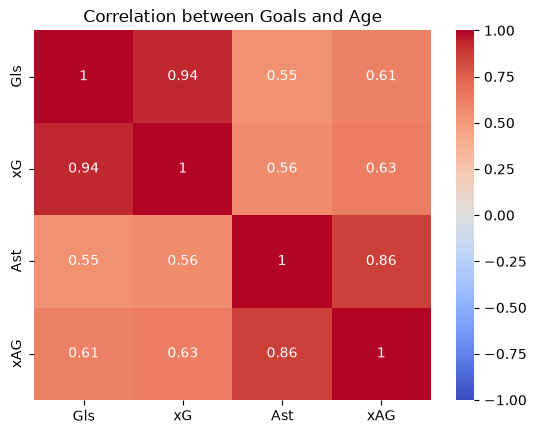

In [38]:
corr = df[['Gls', 'xG', 'Ast', 'xAG']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between Goals and Age')
plt.show()

In [37]:
df.columns

Index(['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP',
       'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt',
       'CrdY', 'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP',
       'PrgR'],
      dtype='str')

In [40]:
gls_by_age_dist = df.groupby('Age')['Gls'].count().reset_index()
gls_by_age_dist

,Age,Gls
0,15,2
1,16,17
2,17,64
3,18,104
4,19,137
5,20,155
6,21,188
7,22,222
8,23,196
9,24,248


<Axes: xlabel='Age', ylabel='Count'>

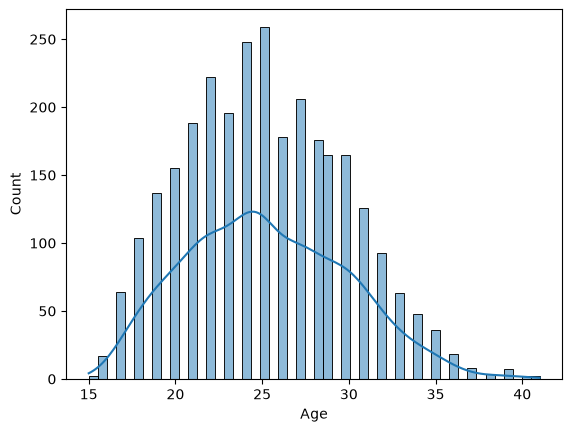

In [42]:
sns.histplot(data=df, x='Age', bins=50, kde=True)